# Grupo 5 — Visualización, comunicación de hallazgos y ética de datos
### Caso de estudio: *Auto MPG* (UCI Machine Learning Repository)

**Fecha:** 30/10/2026

---

**Actividad asignada**
1. Plantear una **pregunta de análisis** sobre Auto MPG.
2. Construir al menos **una visualización estática** y **una visualización interactiva con Plotly**.
3. Convertir la gráfica en un **hallazgo completo**: hallazgo, evidencia, interpretación, limitación y recomendación.
4. Finalizar con una **breve revisión ética del dataset**.


### Hoja de ruta
| # | Sección | Temas del programa que cubre |
|---|---|---|
| 0 | Preparación del entorno y carga de datos | — |
| 1 | Conocer el dataset y sus unidades | Elementos de una gráfica comprensible (unidades y contexto) |
| 2 | Pregunta de análisis y el problema | Selección de visualización según la pregunta |
| 3 | Cuatro preguntas, cuatro gráficas | Comparación, distribución, tendencia y relación (barras, histograma, líneas, dispersión) |
| 4 | Anatomía de una gráfica comprensible | Título, ejes, unidades, contexto · Errores al interpretar visualizaciones |
| 5 | Visualización estática principal | Diagrama de dispersión |
| 6 | Visualización interactiva con Plotly | Introducción a Plotly |
| 7 | De la gráfica al hallazgo | Mostrar vs. comunicar · Estructura del hallazgo |
| 8 | **Reto guiado para los compañeros** | Errores de interpretación · Limitaciones de las inferencias |
| 9 | Revisión ética del dataset | Ética, privacidad y consentimiento, sesgos y representatividad, uso responsable |
| 10 | Criterios para elegir el dataset del proyecto final | Criterios de selección |
| 11 | Cierre | — |

Auto MPG es un conjunto de datos público del UCI Machine Learning Repository (Quinlan, 1993; licencia CC BY 4.0). Reúne 398 modelos de automóviles vendidos en el mercado estadounidense entre 1970 y 1982. Su propósito original fue estudiar y predecir el rendimiento de combustible, medido en millas por galón (mpg).

Cada fila corresponde a un modelo de auto, no a una persona ni a una venta, y se describe con nueve variables:




*   mpg: rendimiento de combustible (variable de interés).
*  cylinders, displacement, horsepower: características del motor (número de cilindros, cilindrada en pulgadas cúbicas y potencia en hp).


*   weight: peso del vehículo en libras.
*   acceleration: tiempo en segundos para pasar de 0 a 60 mph.


*   model_year: año del modelo (70 a 82).
*   origin: región del fabricante (EE. UU., Europa o Japón).


*   name: nombre del modelo.










## 0. Preparación del entorno y carga de datos

Google Colab ya incluye `pandas`, `matplotlib`, `seaborn`, `scipy` y `plotly`. La celda intenta cargar el dataset desde `seaborn`; si falla, lo descarga directamente del repositorio UCI.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import Markdown, display

# Render de Plotly en Colab (en Jupyter local se usa el predeterminado)
try:
    import google.colab  # noqa: F401
    pio.renderers.default = "colab"
except ImportError:
    pass

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

FUENTE = "Fuente: Auto MPG, UCI Machine Learning Repository (Quinlan, 1993). Modelos 1970–1982."

def cargar_auto_mpg():
    try:
        df = sns.load_dataset("mpg")
        origen = "seaborn"
    except Exception:
        url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
        cols = ["mpg", "cylinders", "displacement", "horsepower", "weight",
                "acceleration", "model_year", "origin", "name"]
        df = pd.read_csv(url, sep=r"\s+", names=cols, na_values="?", quotechar='"')
        df["origin"] = df["origin"].map({1: "usa", 2: "europe", 3: "japan"})
        origen = "UCI"
    return df, origen

df_raw, origen_carga = cargar_auto_mpg()
print(f"Datos cargados desde: {origen_carga} | Filas: {df_raw.shape[0]} | Columnas: {df_raw.shape[1]}")
df_raw.head()

Datos cargados desde: seaborn | Filas: 398 | Columnas: 9


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


## 1. Conocer el dataset antes de graficar

Una gráfica comprensible empieza por saber **qué mide cada variable y en qué unidades**. Auto MPG reúne 398 modelos de automóviles vendidos en EE. UU. entre 1970 y 1982.

| Variable | Significado | Unidad original |
|---|---|---|
| `mpg` | Rendimiento de combustible | millas por galón estadounidense |
| `cylinders` | Número de cilindros | conteo |
| `displacement` | Cilindrada del motor | pulgadas cúbicas |
| `horsepower` | Potencia | caballos de fuerza (hp) |
| `weight` | Peso del vehículo | libras |
| `acceleration` | Tiempo de 0 a 60 mph | segundos |
| `model_year` | Año del modelo | 70 = 1970 … 82 = 1982 |
| `origin` | Región del fabricante | EE. UU., Europa, Japón |
| `name` | Nombre del modelo | texto |

**Decisión de comunicación:** el público de esta clase está en Colombia, por lo que convertimos a unidades métricas: **km/L** (1 mpg = 0,425144 km/L) y **kg** (1 lb = 0,453592 kg). Elegir las unidades que entiende la audiencia es parte de *comunicar*, no solo de *mostrar*.

In [3]:
df = df_raw.copy()

# Calidad de datos: valores faltantes
print("Valores faltantes por columna:")
print(df.isna().sum()[df.isna().sum() > 0])

# Variables derivadas en unidades métricas y etiquetas legibles
df["rendimiento_kml"] = df["mpg"] * 0.425144
df["peso_kg"] = df["weight"] * 0.453592
df["anio"] = 1900 + df["model_year"]
df["origen"] = df["origin"].map({"usa": "EE. UU.", "europe": "Europa", "japan": "Japón"})

ORDEN_ORIGEN = ["EE. UU.", "Europa", "Japón"]
COLORES = {"EE. UU.": "#1f77b4", "Europa": "#2ca02c", "Japón": "#d62728"}

df[["rendimiento_kml", "peso_kg", "horsepower", "anio", "origen"]].describe(include="all").round(2)

Valores faltantes por columna:
horsepower    6
dtype: int64


,rendimiento_kml,peso_kg,horsepower,anio,origen
count,398.00,398.00,392.00,398.00,398
unique,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,EE. UU.
freq,NaN,NaN,NaN,NaN,249
mean,10.00,1347.36,104.47,1976.01,NaN
std,3.32,384.12,38.49,3.70,NaN
min,3.83,731.64,46.00,1970.00,NaN
25%,7.44,1008.68,75.00,1973.00,NaN
50%,9.78,1271.65,93.50,1976.00,NaN
75%,12.33,1636.56,126.00,1979.00,NaN


> **Nota de calidad:** `horsepower` tiene 6 valores faltantes (en el archivo original aparecen como `?`). Como nuestra pregunta usa peso y rendimiento, **no eliminamos filas**: conservamos los 398 registros. Si se usara `horsepower`, habría que declarar cómo se trataron esos faltantes.

## 2. Pregunta de análisis y problema planteado

### Situación (el problema)
> Una analista de una entidad de movilidad revisa este histórico y afirma: **«los autos japoneses rinden mucho más combustible que los estadounidenses, así que la clave de la eficiencia es dónde se fabrica el auto»**. Antes de aceptar la afirmación, nos piden revisarla con datos.

### Pregunta de análisis
> **¿En qué medida el peso del vehículo explica las diferencias de rendimiento de combustible (km/L) en Auto MPG, y se mantiene la ventaja por región de origen cuando se comparan autos de peso similar?**


### Selección de la visualización según la pregunta
| Tipo de pregunta | Ejemplo con Auto MPG | Gráfica adecuada |
|---|---|---|
| **Comparación** entre categorías | ¿Qué región tiene mayor rendimiento típico? | Barras |
| **Distribución** de una variable | ¿Cómo se reparte el rendimiento entre los autos? | Histograma |
| **Tendencia** en el tiempo | ¿Cambió el rendimiento entre 1970 y 1982? | Líneas |
| **Relación** entre dos variables numéricas | ¿Los autos más pesados rinden menos? | Dispersión |

Regla práctica: **primero la pregunta, después la gráfica**. Una gráfica elegida «porque se ve bien» suele responder otra pregunta.

## 3. Cuatro preguntas, cuatro gráficas

Exploración breve para ver cómo cada tipo de pregunta pide un tipo de gráfica. Todas incluyen **título informativo, ejes con unidades y fuente**.

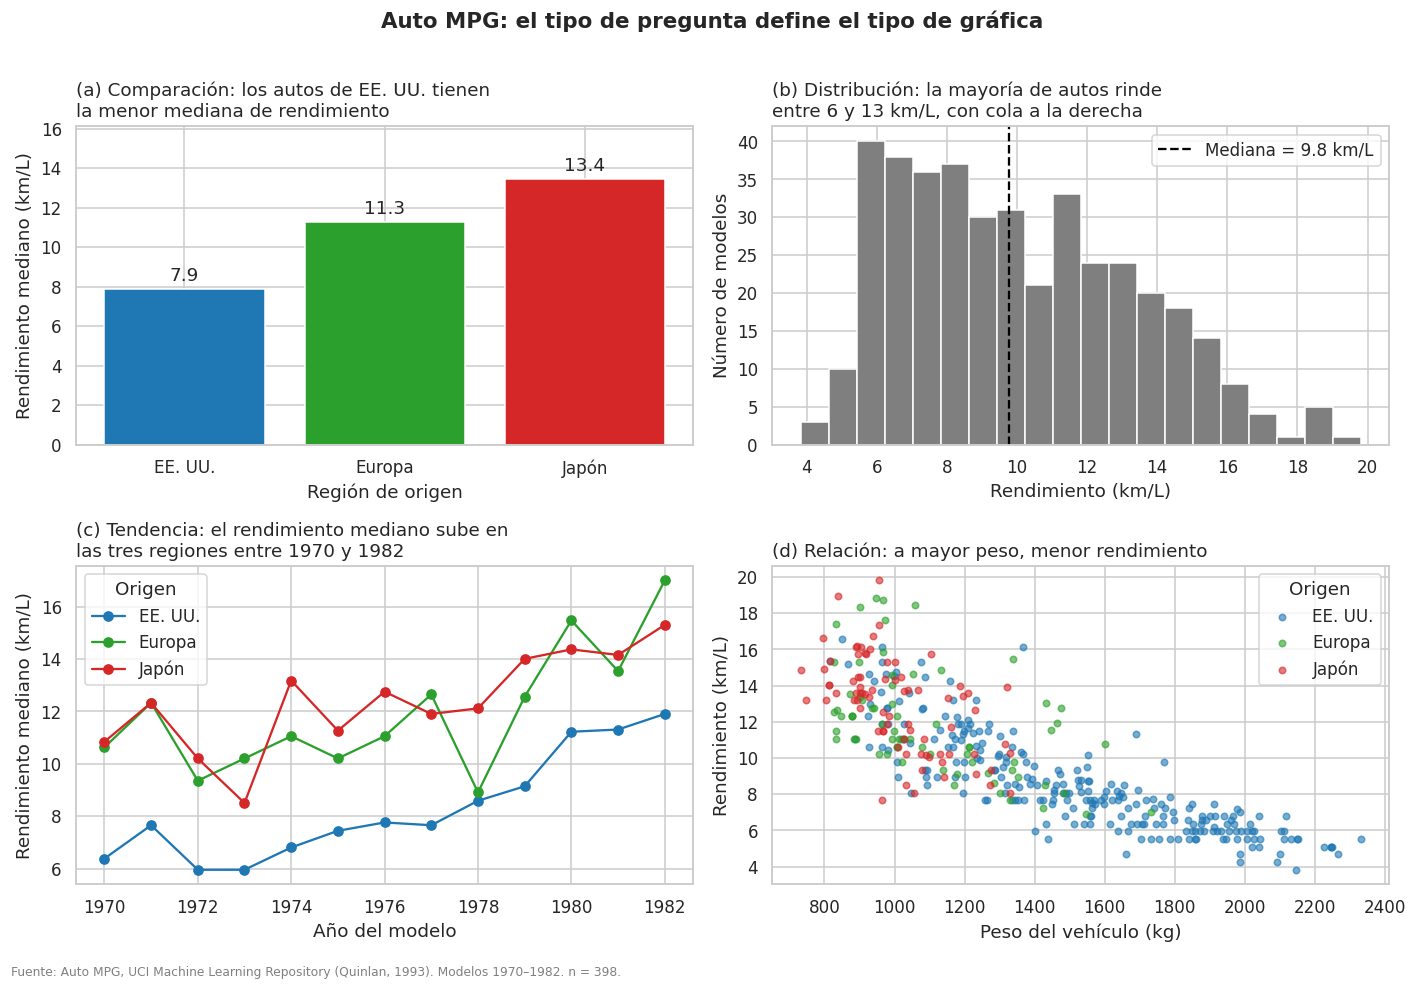

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# (a) COMPARACIÓN -> barras (mediana por origen)
med_origen = df.groupby("origen")["rendimiento_kml"].median().reindex(ORDEN_ORIGEN)
ax = axes[0, 0]
barras = ax.bar(med_origen.index, med_origen.values, color=[COLORES[o] for o in ORDEN_ORIGEN])
ax.bar_label(barras, fmt="%.1f", padding=3)
ax.set_title("(a) Comparación: los autos de EE. UU. tienen\nla menor mediana de rendimiento", loc="left")
ax.set_xlabel("Región de origen")
ax.set_ylabel("Rendimiento mediano (km/L)")
ax.set_ylim(0, med_origen.max() * 1.2)   # eje desde 0: obligatorio en barras

# (b) DISTRIBUCIÓN -> histograma
ax = axes[0, 1]
ax.hist(df["rendimiento_kml"], bins=20, color="#7f7f7f", edgecolor="white")
ax.axvline(df["rendimiento_kml"].median(), color="black", ls="--",
           label=f"Mediana = {df['rendimiento_kml'].median():.1f} km/L")
ax.set_title("(b) Distribución: la mayoría de autos rinde\nentre 6 y 13 km/L, con cola a la derecha", loc="left")
ax.set_xlabel("Rendimiento (km/L)")
ax.set_ylabel("Número de modelos")
ax.legend()

# (c) TENDENCIA -> líneas
tend = df.groupby(["anio", "origen"])["rendimiento_kml"].median().unstack()[ORDEN_ORIGEN]
ax = axes[1, 0]
for o in ORDEN_ORIGEN:
    ax.plot(tend.index, tend[o], marker="o", color=COLORES[o], label=o)
ax.set_title("(c) Tendencia: el rendimiento mediano sube en\nlas tres regiones entre 1970 y 1982", loc="left")
ax.set_xlabel("Año del modelo")
ax.set_ylabel("Rendimiento mediano (km/L)")
ax.legend(title="Origen")

# (d) RELACIÓN -> dispersión
ax = axes[1, 1]
for o in ORDEN_ORIGEN:
    sub = df[df["origen"] == o]
    ax.scatter(sub["peso_kg"], sub["rendimiento_kml"], s=18, alpha=0.6, color=COLORES[o], label=o)
ax.set_title("(d) Relación: a mayor peso, menor rendimiento", loc="left")
ax.set_xlabel("Peso del vehículo (kg)")
ax.set_ylabel("Rendimiento (km/L)")
ax.legend(title="Origen")

fig.suptitle("Auto MPG: el tipo de pregunta define el tipo de gráfica", fontsize=14, fontweight="bold")
fig.text(0.01, 0.005, FUENTE + " n = 398.", fontsize=8, color="gray")
plt.tight_layout(rect=[0, 0.02, 1, 0.97])
plt.show()

**Lectura rápida:** la gráfica (a) parece darle la razón a la analista (Japón y Europa rinden más). Pero la gráfica (d) sugiere que el **peso** también separa a las regiones: los puntos azules (EE. UU.) se concentran a la derecha. Esa tensión es justo lo que vamos a investigar.

## 4. Anatomía de una gráfica comprensible y errores frecuentes

Una gráfica es comprensible cuando un lector que **no estuvo en el análisis** puede entenderla sola. Elementos mínimos:

1. **Título que dice el mensaje** («A mayor peso, menor rendimiento»), no solo las variables («Peso vs mpg»).
2. **Ejes rotulados con unidades** (kg, km/L).
3. **Escalas honestas** (en barras, el eje empieza en 0).
4. **Leyenda** cuando hay color o grupos.
5. **Contexto**: fuente, periodo, tamaño de muestra.

Comparemos la **misma información** mal y bien comunicada:

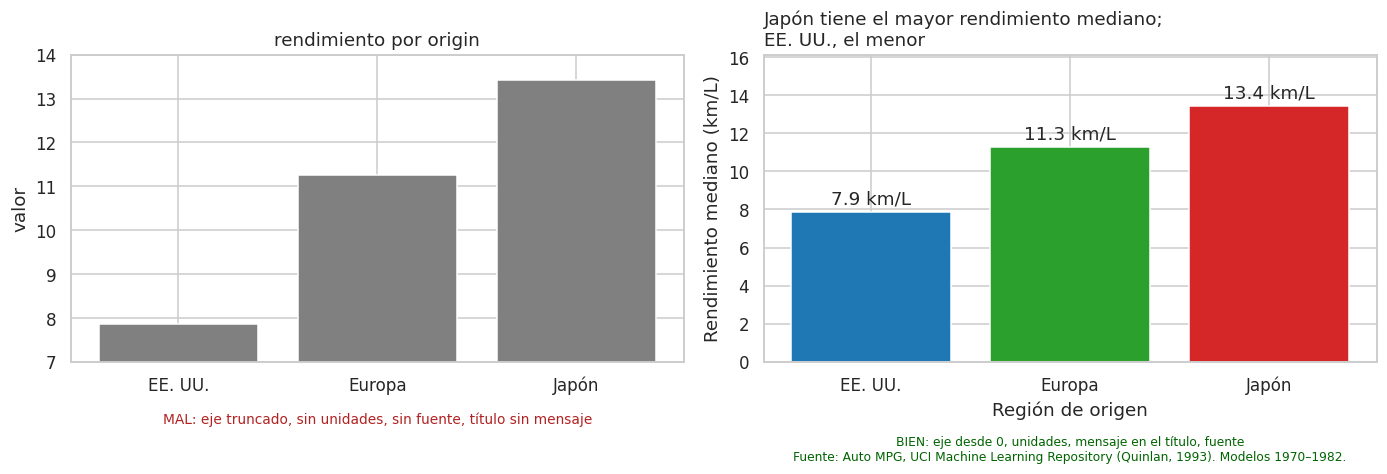

Con el eje truncado, la barra de Japón se ve 7.4 veces más alta que la de EE. UU.
La razón real entre ambos rendimientos es 1.71.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# MAL: eje truncado, sin unidades, título genérico, unidades originales sin explicar
ax = axes[0]
ax.bar(med_origen.index, med_origen.values, color="gray")
ax.set_ylim(7, 14)                     # eje truncado: exagera diferencias
ax.set_title("rendimiento por origin")
ax.set_ylabel("valor")
ax.text(0.5, -0.2, "MAL: eje truncado, sin unidades, sin fuente, título sin mensaje",
        transform=ax.transAxes, ha="center", color="firebrick", fontsize=9)

# BIEN
ax = axes[1]
b = ax.bar(med_origen.index, med_origen.values, color=[COLORES[o] for o in ORDEN_ORIGEN])
ax.bar_label(b, fmt="%.1f km/L", padding=3)
ax.set_ylim(0, med_origen.max() * 1.2)
ax.set_title("Japón tiene el mayor rendimiento mediano;\nEE. UU., el menor", loc="left")
ax.set_xlabel("Región de origen")
ax.set_ylabel("Rendimiento mediano (km/L)")
ax.text(0.5, -0.32, "BIEN: eje desde 0, unidades, mensaje en el título, fuente\n" + FUENTE,
        transform=ax.transAxes, ha="center", color="darkgreen", fontsize=8)

plt.tight_layout()
plt.subplots_adjust(bottom=0.25)
plt.show()

ratio_falso = (med_origen.max() - 7) / (med_origen.min() - 7)
ratio_real = med_origen.max() / med_origen.min()
print(f"Con el eje truncado, la barra de Japón se ve {ratio_falso:.1f} veces más alta que la de EE. UU.")
print(f"La razón real entre ambos rendimientos es {ratio_real:.2f}.")

### Errores frecuentes al interpretar visualizaciones
| Error | Cómo aparece en Auto MPG |
|---|---|
| **Eje truncado** en barras | Hace que una diferencia de 1,7 veces parezca de muchas más (ver celda anterior). |
| **Correlación ≠ causalidad** | Que peso y rendimiento se muevan juntos no prueba, por sí solo, que el peso sea la única causa: motor, cilindros y potencia también cambian con el peso. |
| **Variable de confusión** | Comparar regiones sin considerar el peso puede atribuir al origen un efecto que en buena parte es del peso (lo resolveremos en el reto, Sección 8). |
| **Sobreinterpretar el promedio** | Una mediana alta no significa que *todos* los autos de esa región rindan más. |
| **Generalizar fuera de la muestra** | Estos datos son de 1970–1982: no describen los autos actuales. |
| **Sobreposición de puntos** | En dispersión, muchos puntos encimados ocultan densidad; se mitiga con transparencia (`alpha`). |

## 5. Visualización estática principal (responde la pregunta)

Gráfica de **dispersión** (pregunta de relación) con una **recta de regresión por región** y el coeficiente de correlación en la propia figura.

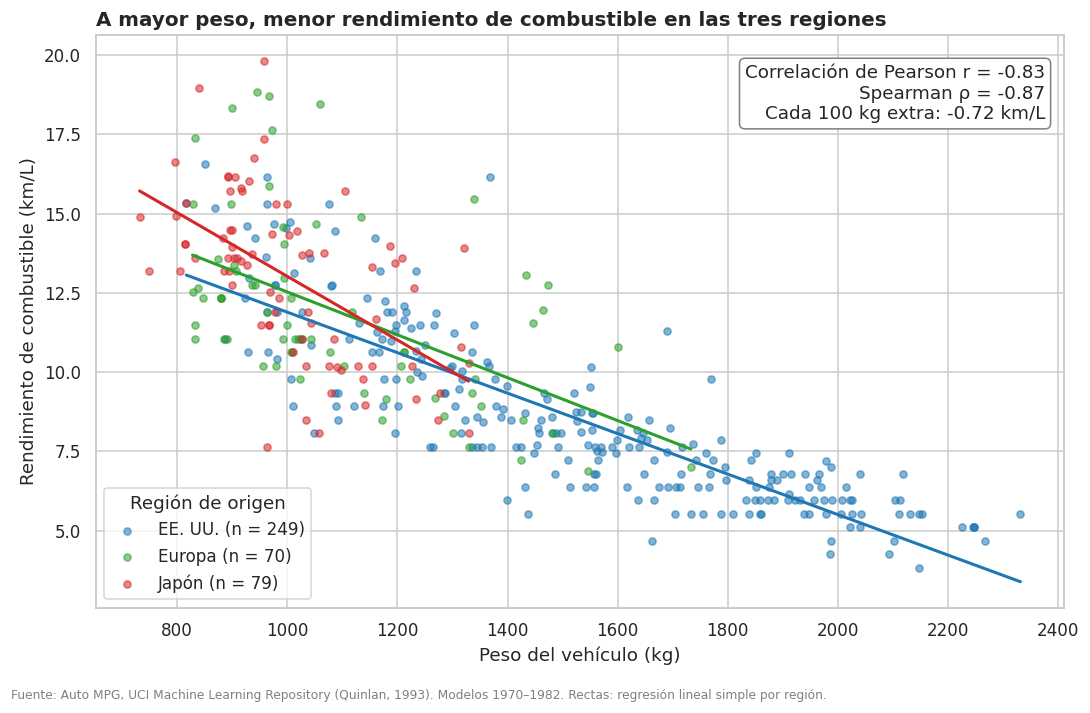

In [6]:
# Estadísticos que usaremos como evidencia
pearson = stats.pearsonr(df["peso_kg"], df["rendimiento_kml"])
spearman = stats.spearmanr(df["peso_kg"], df["rendimiento_kml"])
reg = stats.linregress(df["peso_kg"], df["rendimiento_kml"])

fig, ax = plt.subplots(figsize=(10, 6.5))
for o in ORDEN_ORIGEN:
    sub = df[df["origen"] == o]
    ax.scatter(sub["peso_kg"], sub["rendimiento_kml"], s=22, alpha=0.55,
               color=COLORES[o], label=f"{o} (n = {len(sub)})")
    r_o = stats.linregress(sub["peso_kg"], sub["rendimiento_kml"])
    xs = np.linspace(sub["peso_kg"].min(), sub["peso_kg"].max(), 50)
    ax.plot(xs, r_o.intercept + r_o.slope * xs, color=COLORES[o], lw=2)

ax.set_title("A mayor peso, menor rendimiento de combustible en las tres regiones",
             loc="left", fontsize=13, fontweight="bold")
ax.set_xlabel("Peso del vehículo (kg)")
ax.set_ylabel("Rendimiento de combustible (km/L)")
ax.legend(title="Región de origen")
ax.text(0.98, 0.95,
        f"Correlación de Pearson r = {pearson.statistic:.2f}\n"
        f"Spearman ρ = {spearman.statistic:.2f}\n"
        f"Cada 100 kg extra: {reg.slope*100:.2f} km/L",
        transform=ax.transAxes, ha="right", va="top",
        bbox=dict(boxstyle="round", fc="white", ec="gray"))
fig.text(0.01, 0.01, FUENTE + " Rectas: regresión lineal simple por región.", fontsize=8, color="gray")
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

## 6. Visualización interactiva con Plotly

**Plotly** genera gráficas interactivas en el navegador: permite **pasar el cursor** para ver el detalle de cada punto, **hacer zoom**, **activar o desactivar grupos** haciendo clic en la leyenda y descargar la imagen.

¿Cuándo conviene una gráfica interactiva? Cuando el lector necesita **explorar casos individuales** (¿qué auto es ese punto atípico?) o filtrar grupos. Para un informe impreso, la estática sigue siendo mejor.

Sintaxis básica de `plotly.express`:
```python
px.scatter(datos, x="columna_x", y="columna_y", color="grupo", hover_name="etiqueta")
```

In [7]:
fig = px.scatter(
    df,
    x="peso_kg",
    y="rendimiento_kml",
    color="origen",
    category_orders={"origen": ORDEN_ORIGEN},
    color_discrete_map=COLORES,
    size="cylinders",
    size_max=12,
    opacity=0.7,
    hover_name="name",
    hover_data={"anio": True, "cylinders": True, "horsepower": True,
                "peso_kg": ":.0f", "rendimiento_kml": ":.1f", "origen": False},
    labels={"peso_kg": "Peso del vehículo (kg)",
            "rendimiento_kml": "Rendimiento (km/L)",
            "origen": "Región de origen",
            "anio": "Año", "cylinders": "Cilindros", "horsepower": "Potencia (hp)"},
    title="A mayor peso, menor rendimiento: explore cada modelo (tamaño = n.º de cilindros)",
)

# Rectas de regresión por región (calculadas con scipy, sin dependencias extra)
for o in ORDEN_ORIGEN:
    sub = df[df["origen"] == o]
    r_o = stats.linregress(sub["peso_kg"], sub["rendimiento_kml"])
    xs = np.linspace(sub["peso_kg"].min(), sub["peso_kg"].max(), 50)
    fig.add_trace(go.Scatter(x=xs, y=r_o.intercept + r_o.slope * xs, mode="lines",
                             line=dict(color=COLORES[o], width=2),
                             name=f"Tendencia {o}", hoverinfo="skip"))

fig.update_layout(
    template="plotly_white", height=560, legend_title_text="Región / tendencia",
    annotations=[dict(text=FUENTE, x=0, y=-0.16, xref="paper", yref="paper",
                      showarrow=False, font=dict(size=10, color="gray"))],
    margin=dict(b=90),
)
fig.show()

**Para explorar en clase:**
- Haga clic en «EE. UU.» en la leyenda para ocultarlo: ¿cambia la forma general de la nube de puntos?
- Pase el cursor por los autos de más de 1 800 kg: ¿cuántos cilindros tienen y de qué región son?
- Busque un auto liviano (< 1 000 kg) con bajo rendimiento: ¿qué otra variable podría explicarlo?

In [8]:
# Segunda vista interactiva: tendencia temporal (línea) con detalle al pasar el cursor
tend_long = (df.groupby(["anio", "origen"])["rendimiento_kml"]
               .agg(mediana="median", n="size").reset_index())
fig2 = px.line(tend_long, x="anio", y="mediana", color="origen", markers=True,
               category_orders={"origen": ORDEN_ORIGEN}, color_discrete_map=COLORES,
               hover_data={"n": True},
               labels={"anio": "Año del modelo", "mediana": "Rendimiento mediano (km/L)",
                       "origen": "Región de origen", "n": "Modelos en ese año"},
               title="El rendimiento mediano mejora entre 1970 y 1982 en las tres regiones")
fig2.update_layout(template="plotly_white", height=450)
fig2.show()

## 7. De la gráfica al hallazgo

### Mostrar una gráfica ≠ comunicar un hallazgo
- **Mostrar:** «Aquí está la dispersión de peso contra rendimiento». El lector debe sacar sus propias conclusiones (y puede sacar las equivocadas).
- **Comunicar:** decir **qué encontramos, con qué evidencia, qué significa, hasta dónde vale y qué hacer con ello**.

### Estructura del hallazgo
| Componente | Pregunta que responde |
|---|---|
| **Hallazgo** | ¿Qué encontramos? (una frase) |
| **Evidencia** | ¿Qué cifras y gráficas lo sostienen? |
| **Interpretación** | ¿Qué significa en el contexto? |
| **Limitación** | ¿Hasta dónde se puede afirmar? |
| **Recomendación** | ¿Qué acción o análisis sigue? |

La siguiente celda **calcula las cifras** y redacta la evidencia automáticamente, para que el texto nunca contradiga los datos.

In [9]:
r2 = reg.rvalue ** 2
med = df.groupby("origen").agg(rend=("rendimiento_kml", "median"), peso=("peso_kg", "median")).reindex(ORDEN_ORIGEN)
brecha_global = med.loc["Japón", "rend"] - med.loc["EE. UU.", "rend"]

# Brecha Japón - EE. UU. entre autos livianos (tercil inferior de peso)
df["rango_peso"] = pd.qcut(df["peso_kg"], 3, labels=["Liviano", "Medio", "Pesado"])
tabla_rango = df.groupby(["rango_peso", "origen"], observed=True)["rendimiento_kml"].median().unstack()
brecha_livianos = tabla_rango.loc["Liviano", "Japón"] - tabla_rango.loc["Liviano", "EE. UU."]

display(Markdown(f'''
**Evidencia calculada**
- Correlación peso–rendimiento: Pearson r = **{pearson.statistic:.2f}**; Spearman ρ = **{spearman.statistic:.2f}** (n = {len(df)}).
- El peso, por sí solo, explica cerca del **{r2*100:.0f} %** de la variación del rendimiento (R² de la regresión lineal simple).
- Cada **100 kg** adicionales se asocian con **{abs(reg.slope)*100:.2f} km/L menos**, en promedio.
- Peso mediano: EE. UU. **{med.loc["EE. UU.","peso"]:.0f} kg**, Europa **{med.loc["Europa","peso"]:.0f} kg**, Japón **{med.loc["Japón","peso"]:.0f} kg**.
- Brecha de rendimiento mediano Japón − EE. UU.: **{brecha_global:.1f} km/L** en toda la muestra, pero solo **{brecha_livianos:.1f} km/L** entre autos livianos.
'''))


**Evidencia calculada**
- Correlación peso–rendimiento: Pearson r = **-0.83**; Spearman ρ = **-0.87** (n = 398).
- El peso, por sí solo, explica cerca del **69 %** de la variación del rendimiento (R² de la regresión lineal simple).
- Cada **100 kg** adicionales se asocian con **0.72 km/L menos**, en promedio.
- Peso mediano: EE. UU. **1526 kg**, Europa **1016 kg**, Japón **977 kg**.
- Brecha de rendimiento mediano Japón − EE. UU.: **5.6 km/L** en toda la muestra, pero solo **1.0 km/L** entre autos livianos.


### Hallazgo completo

> **Hallazgo.** En Auto MPG, el **peso del vehículo** es el factor más fuertemente asociado al rendimiento de combustible: los autos más pesados rinden sistemáticamente menos, en las tres regiones de origen.
>
> **Evidencia.** La correlación entre peso y rendimiento es fuerte y negativa (r ≈ −0,83; ρ ≈ −0,87; n = 398). El peso explica cerca del 69 % de la variación del rendimiento, y cada 100 kg adicionales se asocian con unos 0,72 km/L menos. Los autos estadounidenses tienen un peso mediano cercano a 1 530 kg, frente a unos 1 020 kg (Europa) y 980 kg (Japón). La brecha de rendimiento Japón − EE. UU. pasa de unos 5,6 km/L en toda la muestra a cerca de 1 km/L al comparar solo autos livianos.
>
> **Interpretación.** La afirmación «la clave es dónde se fabrica el auto» es **incompleta**: buena parte de la ventaja aparente de Japón y Europa se explica porque sus autos eran más livianos. El origen funciona en gran medida como un indicador del tamaño del vehículo.
>
> **Limitación.** Es una asociación observacional, no un efecto causal: el peso viaja junto con la cilindrada, la potencia y los cilindros. Los datos cubren 1970–1982, están dominados por autos de EE. UU. (≈ 63 %) y **no hay autos japoneses pesados** en la muestra, por lo que no puede compararse el origen en ese rango. Además, la relación no es perfectamente lineal (se curva en pesos bajos).
>
> **Recomendación.** Al comparar la eficiencia entre fabricantes o regiones, **comparar dentro de rangos de peso similares** (o ajustar por peso en un modelo). Para decisiones actuales, repetir el análisis con datos recientes (por ejemplo, homologaciones de consumo vigentes) antes de concluir.

## 8. Reto guiado para los compañeros

### El problema
La analista insiste: *«la gráfica de barras demuestra que el origen es lo que importa»*. Ustedes van a **comprobar si la ventaja japonesa se mantiene cuando se comparan autos de peso parecido**.

**Instrucciones:** completen las celdas marcadas con `# TODO`. Cada paso tiene una **pista** y una **celda de solución oculta** (en Colab, haga doble clic en la celda «Solución» para ver el código; o simplemente ejecútela).

---
### Paso 1 — Agrupar los autos en tres rangos de peso
**Pista:** `pd.qcut(serie, 3, labels=[...])` divide en tres grupos con aproximadamente la misma cantidad de autos (terciles).

In [ ]:
# TODO: cree la columna "rango_peso" con pd.qcut y las etiquetas "Liviano", "Medio", "Pesado"
# df["rango_peso"] = ...

# Verificación: ¿cuántos autos hay de cada región en cada rango?
# pd.crosstab(df["rango_peso"], df["origen"])

In [10]:
#@title Solución — Paso 1 (doble clic para ver el código)
df["rango_peso"] = pd.qcut(df["peso_kg"], 3, labels=["Liviano", "Medio", "Pesado"])
display(df.groupby("rango_peso", observed=True)["peso_kg"].agg(["min", "max"]).round(0)
          .rename(columns={"min": "Peso mínimo (kg)", "max": "Peso máximo (kg)"}))
pd.crosstab(df["rango_peso"], df["origen"])[ORDEN_ORIGEN]

,Peso mínimo (kg),Peso máximo (kg)
rango_peso,,
Liviano,732.0,1086.0
Medio,1089.0,1491.0
Pesado,1498.0,2331.0


origen,EE. UU.,Europa,Japón
rango_peso,,,
Liviano,34,42,58
Medio,85,25,21
Pesado,130,3,0


**Pregunta de control 1:** ¿Cuántos autos japoneses hay en el rango «Pesado»? ¿Qué implica eso para la comparación?

---
### Paso 2 — Calcular el rendimiento mediano por rango de peso y origen
**Pista:** `df.groupby(["rango_peso", "origen"], observed=True)["rendimiento_kml"].median().unstack()`

In [ ]:
# TODO: calcule la tabla de medianas (filas = rango de peso, columnas = origen)
# tabla = ...

In [11]:
#@title Solución — Paso 2
tabla = (df.groupby(["rango_peso", "origen"], observed=True)["rendimiento_kml"]
           .median().unstack()[ORDEN_ORIGEN].round(2))
tabla

origen,EE. UU.,Europa,Japón
rango_peso,,,
Liviano,12.75,12.33,13.71
Medio,9.48,9.78,10.20
Pesado,6.38,7.01,NaN


---
### Paso 3 — Graficar la comparación controlada
**Pista:** la pregunta es de **comparación** (origen) dentro de categorías (rango de peso) → **barras agrupadas**. Recuerden: título con mensaje, ejes con unidades, eje desde 0 y fuente.

In [ ]:
# TODO: construya un gráfico de barras agrupadas (puede ser con matplotlib, seaborn o plotly)

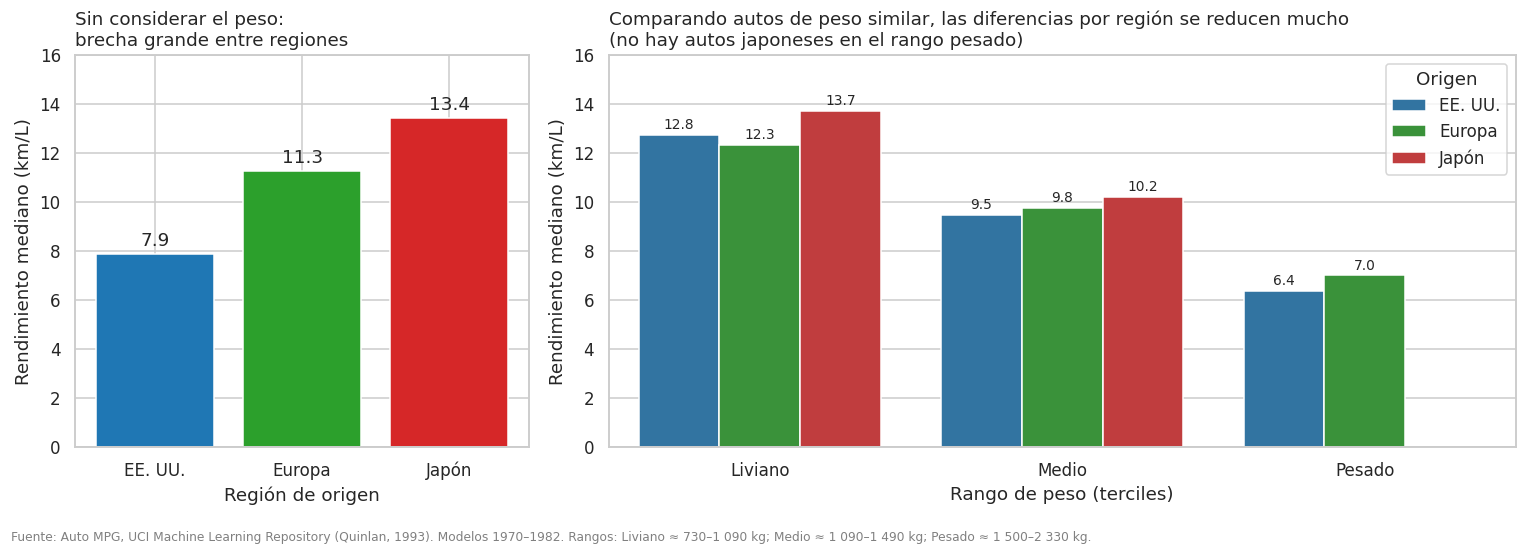

In [12]:
#@title Solución — Paso 3
datos_barras = tabla.reset_index().melt(id_vars="rango_peso", var_name="origen",
                                        value_name="rend_mediano").dropna()
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 2]})

# Izquierda: comparación sin controlar por peso (lo que vio la analista)
b = axes[0].bar(med_origen.index, med_origen.values, color=[COLORES[o] for o in ORDEN_ORIGEN])
axes[0].bar_label(b, fmt="%.1f", padding=3)
axes[0].set_ylim(0, 16)
axes[0].set_title("Sin considerar el peso:\nbrecha grande entre regiones", loc="left")
axes[0].set_xlabel("Región de origen")
axes[0].set_ylabel("Rendimiento mediano (km/L)")

# Derecha: comparación dentro de cada rango de peso
sns.barplot(data=datos_barras, x="rango_peso", y="rend_mediano", hue="origen",
            hue_order=ORDEN_ORIGEN, palette=COLORES, ax=axes[1])
for cont in axes[1].containers:
    axes[1].bar_label(cont, fmt="%.1f", padding=2, fontsize=9)
axes[1].set_ylim(0, 16)
axes[1].set_title("Comparando autos de peso similar, las diferencias por región se reducen mucho\n"
                  "(no hay autos japoneses en el rango pesado)", loc="left")
axes[1].set_xlabel("Rango de peso (terciles)")
axes[1].set_ylabel("Rendimiento mediano (km/L)")
axes[1].legend(title="Origen")

fig.text(0.01, 0.0, FUENTE + " Rangos: Liviano ≈ 730–1 090 kg; Medio ≈ 1 090–1 490 kg; Pesado ≈ 1 500–2 330 kg.",
         fontsize=8, color="gray")
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

**Pregunta de control 2:** comparen la brecha Japón − EE. UU. en la gráfica de la izquierda con la brecha en el rango «Liviano». ¿Cuánto se redujo?

---
### Paso 4 — Redactar el hallazgo con la estructura completa
Completen en la celda de texto siguiente (doble clic para editar). Usen **cifras** de la tabla del Paso 2.

✏️ **Nuestro hallazgo (completar en clase)**

- **Hallazgo:** …
- **Evidencia:** …
- **Interpretación:** …
- **Limitación:** …
- **Recomendación:** …

In [ ]:
#@title Solución — Paso 4 (redacción de referencia)
t = tabla
display(Markdown(f'''
- **Hallazgo:** la ventaja de rendimiento de los autos japoneses sobre los estadounidenses **se reduce drásticamente** al comparar autos de peso similar.
- **Evidencia:** sin controlar por peso, la brecha mediana Japón − EE. UU. es de **{brecha_global:.1f} km/L**; entre autos livianos es de **{t.loc["Liviano","Japón"]-t.loc["Liviano","EE. UU."]:.1f} km/L** y entre autos medianos de **{t.loc["Medio","Japón"]-t.loc["Medio","EE. UU."]:.1f} km/L**. EE. UU. tiene {int((df.query("origen=='EE. UU.'")["rango_peso"]=="Pesado").sum())} autos pesados; Japón, ninguno.
- **Interpretación:** la conclusión «el origen es lo que importa» confunde origen con tamaño: el **peso actúa como variable de confusión**. Queda una ventaja pequeña de Japón que podría deberse a otros factores (tecnología de motor, cilindrada).
- **Limitación:** solo tres rangos de peso y medianas; grupos pequeños en algunas celdas (p. ej., 3 autos europeos pesados); datos observacionales de 1970–1982.
- **Recomendación:** no atribuir diferencias de eficiencia al país de origen sin controlar por peso; como siguiente paso, ajustar un modelo de regresión con peso y origen a la vez.
'''))

**Pregunta de control 3 (para discusión):** ¿la conclusión «los autos japoneses no son más eficientes» sería correcta? *(No: la evidencia muestra que la ventaja es mucho menor de lo que parecía, no que desaparezca; y en el rango pesado no hay datos para comparar.)*

## 9. Revisión ética breve del dataset

La ética de datos pregunta **de dónde vienen los datos, a quién representan, a quién podrían afectar y qué afirmaciones permiten** hacer.

| Dimensión | Revisión aplicada a Auto MPG |
|---|---|
| **Origen y licencia** | Dataset público del UCI Machine Learning Repository, derivado de la biblioteca StatLib (Carnegie Mellon) y usado por Quinlan (1993). Licencia CC BY 4.0: se puede usar y adaptar citando la fuente. |
| **Privacidad y consentimiento** | Las unidades de análisis son **modelos de automóviles**, no personas. No contiene datos personales, por lo que no hay riesgo de reidentificación ni se requiere consentimiento individual. |
| **Sesgos y representatividad** | ≈ 63 % de los modelos son de EE. UU.; Europa y Japón están subrepresentados y **no hay autos japoneses pesados**. Cada fila es un modelo, no una venta: un modelo popular pesa lo mismo que uno marginal, así que **no representa la flota real** que circulaba. Solo incluye autos vendidos en el mercado estadounidense. |
| **Vigencia** | Modelos 1970–1982. La tecnología (inyección, híbridos, eléctricos) y las normas de consumo cambiaron; **no describe autos actuales ni el mercado colombiano**. |
| **Calidad de la medición** | El rendimiento proviene de mediciones de laboratorio de la época, no del uso real en carretera. Hay 6 valores faltantes de potencia y 8 registros adicionales sin `mpg` se excluyeron en la versión original del dataset. |
| **Uso responsable** | Es adecuado para **enseñanza y análisis exploratorio**. No debería usarse para afirmar que un país fabrica autos «mejores» ni para decisiones regulatorias o comerciales actuales. |
| **Límites de las inferencias** | Las relaciones son **asociaciones observacionales**; no prueban causalidad. Al comunicar, hay que evitar lenguaje causal («el peso *causa*…») y declarar el periodo y la muestra. |

**Conclusión ética:** el riesgo de daño a personas es bajo, pero el **riesgo de mala interpretación** es alto si se generalizan los resultados. El uso responsable exige declarar el periodo, el desbalance por origen y el carácter no causal de los hallazgos.

In [ ]:
# Evidencia cuantitativa de la revisión ética: representatividad
rep = (df["origen"].value_counts().reindex(ORDEN_ORIGEN).to_frame("Modelos")
         .assign(**{"% de la muestra": lambda x: (x["Modelos"] / x["Modelos"].sum() * 100).round(1)}))
display(rep)
print("Faltantes en horsepower:", df["horsepower"].isna().sum())
print("Rango de años:", df["anio"].min(), "–", df["anio"].max())

## 10. Criterios para seleccionar el dataset del proyecto final

Lo aprendido con Auto MPG sirve como lista de verificación para elegir el dataset del proyecto final:

| Criterio | Pregunta guía | ¿Cómo sale Auto MPG? |
|---|---|---|
| **Pertinencia** | ¿Permite responder una pregunta de análisis clara? | ✅ Sí (relación peso–rendimiento) |
| **Tamaño suficiente** | ¿Hay observaciones suficientes en cada grupo que se quiere comparar? | ⚠️ Algunos grupos son pequeños |
| **Variables y unidades documentadas** | ¿Existe diccionario de datos? | ✅ Sí |
| **Calidad** | ¿Cuántos faltantes, errores o duplicados tiene? | ✅ Pocos faltantes (6) |
| **Vigencia** | ¿Los datos son actuales para la pregunta? | ❌ 1970–1982 |
| **Representatividad** | ¿La muestra representa a la población de interés? | ⚠️ Sesgada hacia EE. UU. |
| **Licencia y fuente** | ¿Se puede usar y citar legalmente? | ✅ CC BY 4.0, con cita |
| **Privacidad** | ¿Contiene datos personales? ¿Hay consentimiento? | ✅ No contiene datos personales |
| **Variedad de tipos de variable** | ¿Hay categóricas, numéricas y temporales para varias gráficas? | ✅ Sí |

## 11. Cierre

**Ideas clave**
1. **La pregunta elige la gráfica:** comparación → barras; distribución → histograma; tendencia → líneas; relación → dispersión.
2. **Una gráfica comprensible** tiene título con mensaje, ejes con unidades, escalas honestas, leyenda y contexto.
3. **Mostrar no es comunicar:** un hallazgo completo incluye evidencia, interpretación, limitación y recomendación.
4. **Cuidado con las variables de confusión:** la ventaja aparente por origen era, en buena parte, una diferencia de peso.
5. **Ética de datos** no es solo privacidad: también es representatividad, vigencia y no afirmar más de lo que los datos permiten.

**Pregunta final para el grupo:** si tuvieran que presentar este hallazgo a una entidad de movilidad en Colombia hoy, ¿qué datos adicionales pedirían antes de recomendar una política?

---
**Referencias**
- Quinlan, J. R. (1993). *Combining instance-based and model-based learning*. Proceedings of the Tenth International Conference on Machine Learning, 236–243.
- Quinlan, R. (1993). *Auto MPG* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5859H
- Plotly Technologies Inc. *Plotly Python Graphing Library*. https://plotly.com/python/